# GRANAP in metafspm: cross sections as a structural component

This tutorial is for GRANAP developers. It shows what the metafspm port changes for them, on single cross sections:

- **GRANAP generates into the plant graph.** A section is no longer a standalone `Organ` object: its cells, walls,
  wall junctions and hydraulic network are written into metafspm's multiscale plant graph (MPG), below the
  segment (a `SubOrgan`) they belong to, as `Compartment`s (nodes) and `Connection`s (edges).
- **The anatomy is a component.** `GranapAnatomy` is a metafspm `StructuralComponent` with declared inputs (what it
  reads from an architecture model: each segment's radius, length, distance from the tip) and declared outputs
  (what another model, such as MECHA's hydraulics, reads: tissues, cell areas, wall lengths, the network's edges).
  Coupling is through these variables only.
- **One template per class, a copy per segment.** Segments are binned into anatomy classes (by default their
  diameter); GRANAP generates each class once and copies it onto every segment of that class. Plants and segments
  are parametrized without touching GRANAP's code: by preset, by class, by class input, by plant.
- **It follows the plant's development.** When a segment appears or changes class, the component gives it its
  anatomy at the next call; the DataStructure is rewired around it.

Everything here runs on GRANAP's main package (`openalea.granap`, the port); the original code is kept as
`openalea.granap.legacy` for comparisons only (`test/comparison`, `example/comparison`).

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Polygon as PolygonPatch

from openalea.metafspm.coupling.choregrapher import Choregrapher
from openalea.metafspm.coupling.component import StructuralComponent
from openalea.metafspm.data_structure.configs import PropsConfig
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population

from openalea.granap.metafspm.component import GranapAnatomy, OrganAnatomy, junction_rules
from openalea.granap.metafspm.library import AnatomyLibrary, ClassInput, find_template, preset_parameters

Choregrapher().add_simulation_time_step(3600.)          # metafspm's simulation time step (s), once per session

## 1. The architecture: what GRANAP is given

An architecture model builds the plant graph down to the segments (`SubOrgan`) and gives each its radius, length
and distance from the tip (m). Here a minimal stand-in: one root axis with one segment. It is a
`StructuralComponent` whose `initiate_plant` builds the plant when the population is created.

In [2]:
RADIUS, LENGTH = 0.55e-3, 2e-4                          # m: GRANAP's monocot root preset, a 200 µm section


class OneSegmentRoot(StructuralComponent):
    @classmethod
    def initiate_plant(cls, g, plant, parameters):
        s, L = g.scales, g.labels
        complex_ = plant
        for scale, label in ((s.Axis, L.Axis.Root), (s.GrowthUnit, L.GrowthUnit.Root), (s.Phytomer, L.Phytomer.Root),
                             (s.Organ, L.Organ.RootInternode)):
            complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
        segment = g.add_component(complex_, **PropsConfig(scale=s.SubOrgan, edge_type='/',
                                                          label=L.SubOrgan.RootSegment))
        g.property("radius")[segment] = RADIUS
        g.property("length")[segment] = LENGTH
        g.property("distance_from_tip")[segment] = 0.

## 2. The anatomy component, initialised

Three steps, the same in every metafspm model:

1. **build the population**: `build_population` creates the plants and calls each initiator's `initiate_plant`
   in order: the architecture first, then `GranapAnatomy`, which gives every root segment its section;
2. **open a DataStructure** on the graph: its nodes are the `Compartment`s, its edges the `Connection`s, and
   `junction_rules` joins the conducting cells (xylem, phloem) of successive sections;
3. **instantiate the component** on it and call it: it registers its declared variables and computes the 3D
   quantities (wall surfaces, cell volumes) from the segments' lengths.

In [3]:
plants = pd.DataFrame([dict(plant="p0", model=None, x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
g, _ = build_population(plants, initiators=(OneSegmentRoot, GranapAnatomy))
g.convert_properties_to_arraydict()
ds = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g))
anatomy = GranapAnatomy(data_structure=ds)
anatomy()
print(f"{ds.n_nodes()} Compartments, {ds.n_edges()} Connections")

8269 Compartments, 20334 Connections


### What the component writes, and where

The section lives in the graph under its segment: `Layer`s (GRANAP's tissue layers), and the hydraulic network's
`Compartment`s (`kind` 0 protoplast, 1 wall, 2 wall junction) and `Connection`s (`network_path`: membrane,
wall, plasmodesmata, air link...). Every declared variable is read and written through the DataStructure, one
value per entity, as numpy arrays.

In [4]:
segment = int(ds.entity_ids("SubOrgan")[0])
print(f"segment {segment}: {len(g.components_at_scale(segment, scale=g.scales.Layer))} Layers")
kind = ds.get("kind")
print("Compartments by kind:", {name: int((kind == k).sum()) for k, name in ((0, "protoplast"), (1, "wall"),
                                                                             (2, "junction"))})
paths = {0: "membrane", 1: "wall_air", 2: "wall", 3: "plasmodesmata", 4: "air_link", 5: "axial junction"}
path = ds.get("network_path")
print("Connections by path:", {name: int((path == k).sum()) for k, name in paths.items() if (path == k).any()})

segment 16: 398 Layers
Compartments by kind: {'protoplast': 1380, 'wall': 4134, 'junction': 2755}
Connections by path: {'membrane': 8100, 'wall': 8268, 'plasmodesmata': 3966}


The declared interface: what the component reads (inputs, role `Architecture`) and writes (state variables).
Another component never imports GRANAP's classes: it declares the same variables as its inputs.

In [5]:
declared = [(name, f.metadata.get("variable_type"), f.metadata.get("unit"), f.metadata.get("description"))
            for name, f in GranapAnatomy.__dataclass_fields__.items() if f.metadata.get("variable_type")]
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(declared, columns=["variable", "type", "unit", "description"]).set_index("variable")

,type,unit,description
variable,,,
radius,input,m,the segment's radius (the diameter class input)
distance_from_tip,input,m,the segment's distance from its axis' tip
length,input,m,"the segment's length, broadcast to its Compartments"
anatomy_template,state_variable,,the segment's anatomy template (-1: none)
tissue,state_variable,,the protoplast's tissue (None: a wall or a junction)
kind,state_variable,,"0 protoplast, 1 wall, 2 wall junction, 3 a leaf organ's surface"
pore_width,state_variable,mm,a stomatal pore's aperture width in the section (NaN: not a pore)
pore_depth,state_variable,mm,a stomatal pore's depth through the epidermis (NaN: not a pore)
cgroup,state_variable,,the protoplast's MECHA cell group (NaN: apoplast)


In [6]:
protoplasts = kind == 0
tissues = pd.Series(ds.get("tissue")[protoplasts]).value_counts()
print("protoplasts by tissue:\n", tissues.to_string())
print(f"cell area {ds.get('cell_area')[protoplasts].sum():.4f} mm², walls {ds.get('wall_length').sum():.2f} mm long")

protoplasts by tissue:
 stele         406
air space     367
cortex        206
epidermis     168
pericycle      97
exodermis      79
endodermis     32
protoxylem     10
phloem         10
metaxylem       5
cell area 0.5283 mm², walls 43.00 mm long


### Drawing a section from the graph

A section's polygons stay in its template (one per class); its Compartments know their template row. Positions
(`section_x`, `section_y`) are on every Compartment, so the network is drawn from the DataStructure alone.

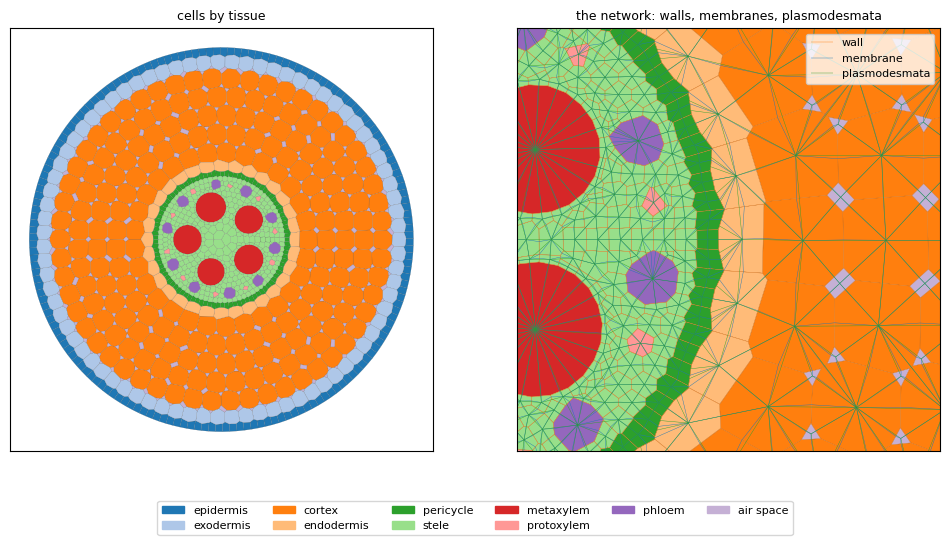

In [7]:
def libraries(component):
    return [organ.library for organ in component.organs().values()]


def draw_section(ax, g, ds, segment, component, network=False, title=None):
    """The segment's cells, coloured by tissue (their template's polygons); optionally its network's edges."""
    template = find_template(libraries(component), int(g.property("anatomy_template")[segment]))
    owners = g.compartments_by_owner(g.scales.SubOrgan)[segment]
    tissue, row = g.property("tissue"), g.property("template_row")
    patches, colours = [], []
    for v in owners:
        if v in row and tissue.get(v) is not None:
            polygon = template.polygons[int(row[v])]
            if polygon is not None and polygon.geom_type == "Polygon":
                patches.append(PolygonPatch(np.asarray(polygon.exterior.coords)))
                colours.append(TISSUE_COLOURS.setdefault(tissue[v], PALETTE[len(TISSUE_COLOURS) % len(PALETTE)]))
    ax.add_collection(PatchCollection(patches, facecolor=colours, edgecolor="0.3", linewidth=0.1))
    if network:
        index = np.flatnonzero(np.isin(ds.entity_ids("SubOrgan")[ds.owner("SubOrgan")], [segment]))
        view = ds.to_graph_view()
        x, y = ds.get("section_x"), ds.get("section_y")
        local = np.isin(view.tail, index) & np.isin(view.head, index)
        for code, colour in ((2, "tab:orange"), (0, "tab:blue"), (3, "tab:green")):
            e = np.flatnonzero(local & (ds.get("network_path") == code))
            lines = np.stack([np.c_[x[view.tail[e]], y[view.tail[e]]], np.c_[x[view.head[e]], y[view.head[e]]]], 1)
            ax.add_collection(LineCollection(lines, colors=colour, linewidths=0.3, label=paths[code]))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_title(title or f"segment {segment}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])


TISSUE_COLOURS = {}                                                  # one colour per tissue, across the tutorial
PALETTE = [matplotlib.colormaps[name](i) for name, n in (("tab20", 20), ("tab20b", 20), ("Set3", 12))
           for i in range(n)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
draw_section(axes[0], g, ds, segment, GranapAnatomy, title="cells by tissue")
draw_section(axes[1], g, ds, segment, GranapAnatomy, network=True, title="the network: walls, membranes, plasmodesmata")
axes[1].set_xlim(0.05, 0.25)
axes[1].set_ylim(-0.1, 0.1)
axes[1].legend(loc="upper right", fontsize=8)
fig.legend(handles=[matplotlib.patches.Patch(color=c, label=t) for t, c in TISSUE_COLOURS.items()],
           loc="lower center", ncol=6, fontsize=8)
plt.show()

## 3. Parametrizing the anatomy, without touching GRANAP

A segment's anatomy is the template of its **class**. The parameters of a class come, in order, from:

1. the **library's preset** (`AnatomyLibrary(parameters=preset_parameters("for_dicot_root"))`: any
   `OrganInputData` preset, or your own function `parameters(key, overrides=...)`);
2. the **plant's overrides** (its scenario's `granap_overrides`: a genotype);
3. the **class's own overrides** (`class_parameters`: a dict or a function of the class key);
4. the **class inputs' targets** (`ClassInput(..., target=(section, field))`: a segment's input binned and set as a
   GRANAP field).

Overrides are `{section: {field: value}}`, GRANAP's `OrganInputData` sections and fields. Templates are keyed by
(class, plant overrides): segments and plants parametrized alike share one.

To show them, an axis of several segments, built from a table of (radius, distance from the tip).

In [8]:
def root_axis(segments):
    """A root axis of segments [(radius m, distance from tip m), ...], base first."""
    class Axis(StructuralComponent):
        @classmethod
        def initiate_plant(cls, g, plant, parameters):
            s, L = g.scales, g.labels
            complex_ = plant
            for scale, label in ((s.Axis, L.Axis.Root), (s.GrowthUnit, L.GrowthUnit.Root),
                                 (s.Phytomer, L.Phytomer.Root), (s.Organ, L.Organ.RootInternode)):
                complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
            previous = None
            for radius, distance in segments:
                props = PropsConfig(scale=s.SubOrgan, edge_type='<' if previous else '/', label=L.SubOrgan.RootSegment)
                v = g.add_child(previous, **props) if previous else g.add_component(complex_, **props)
                g.property("radius")[v], g.property("length")[v] = radius, LENGTH
                g.property("distance_from_tip")[v] = distance
                previous = v
    return Axis


def build(architecture, component, scenarios=({},)):
    """The population (one plant per scenario), its DataStructure and its anatomy component, called once."""
    table = pd.DataFrame([dict(plant=f"p{i}", model=None, x=float(i), y=0., z=0., rotation=0.,
                               scenario={"parameters": dict(p)}) for i, p in enumerate(scenarios)])
    g, _ = build_population(table, initiators=(architecture, component))
    g.convert_properties_to_arraydict()
    ds = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g))
    instance = component(data_structure=ds)
    instance()
    return g, ds, instance


def gallery(g, ds, component, titles=None, columns=4, size=3.6):
    segments = [int(v) for v in ds.entity_ids("SubOrgan")]
    rows = -(-len(segments) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(size * columns, size * rows), squeeze=False)
    for ax, s, title in zip(axes.flat, segments, titles or [None] * len(segments)):
        draw_section(ax, g, ds, s, component, title=title)
    for ax in axes.flat[len(segments):]:
        ax.axis("off")
    fig.legend(handles=[matplotlib.patches.Patch(color=c, label=t) for t, c in TISSUE_COLOURS.items()],
               loc="lower center", ncol=7, fontsize=7)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

### 3a. A preset, and the default class: the diameter

The default class inputs bin the diameter by 0.05 mm (and read the distances from the tip and from the root-shoot
junction without binning: width 0). Three segments, two diameters: two templates, three copies. The diameter is
only a key here: the preset gives the same anatomy to both classes unless a class's parametrization says
otherwise (3b).

In [9]:
class DicotRoot(GranapAnatomy):
    library = AnatomyLibrary(parameters=preset_parameters("for_dicot_root"))


axis = root_axis([(0.40e-3, 0.), (0.40e-3, 0.), (0.25e-3, 0.)])
g1, ds1, _ = build(axis, DicotRoot)
print("classes (diameter mm, distance from tip, from junction):",
      {int(s): g1.property("anatomy_class")[int(s)] for s in ds1.entity_ids("SubOrgan")})
print("templates generated:", len(DicotRoot.library.templates), "for", len(ds1.entity_ids("SubOrgan")), "segments")

classes (diameter mm, distance from tip, from junction): {16: (0.8, 0.0, 0.0), 17: (0.8, 0.0, 0.0), 18: (0.5, 0.0, 0.0)}
templates generated: 2 for 3 segments


### 3b. A class's own parametrization, and class inputs that set GRANAP fields

`root` (an `OrganAnatomy`) gives the roots their library and class inputs. `class_parameters` maps a class key (the class inputs' binned values) to overrides: here the thinner roots get two
cortex layers. A `ClassInput` with a `target` sets a GRANAP field from a segment's input: here the aerenchyma
proportion grows with the distance from the tip, computed by the input's `compute` function and binned by 0.1.

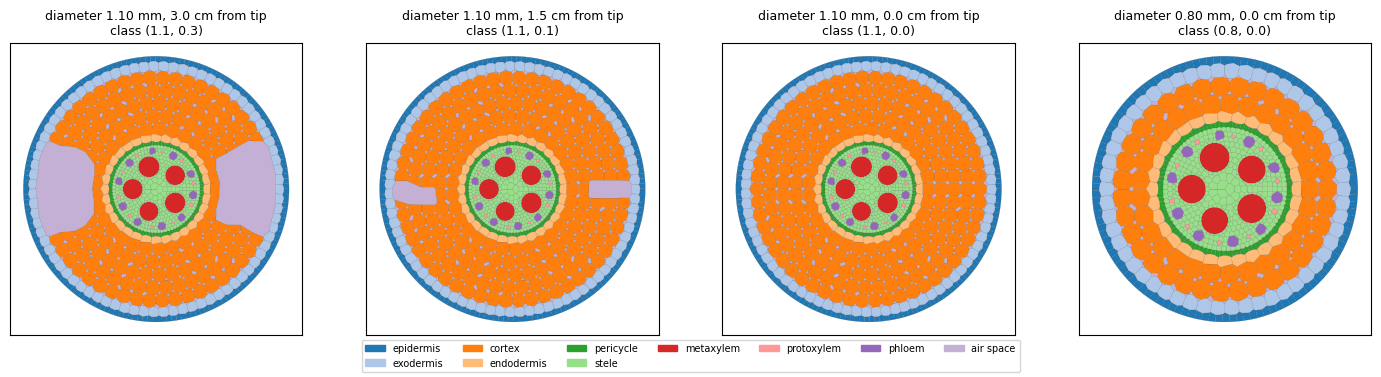

In [10]:
def thinner_roots(key):
    diameter = key[0]
    return {"cortex": {"n_layers": 2}} if diameter < 0.9 else {}


def aerenchyma_with_age(g, segment):
    return min(0.3, 10. * float(g.property("distance_from_tip")[segment]))     # m from the tip -> proportion


class MonocotRoot(GranapAnatomy):
    root = OrganAnatomy(AnatomyLibrary(class_parameters=thinner_roots), class_inputs=(
        ClassInput("radius", 0.05, 2000.),                                    # the diameter (mm, from m), by 0.05
        ClassInput("aerenchyma", 0.1, 1., target=("aerenchyma", "aerenchyma_proportion"),
                   compute=aerenchyma_with_age)))

axis = root_axis([(0.55e-3, 0.03), (0.55e-3, 0.015), (0.55e-3, 0.), (0.40e-3, 0.)])
g2, ds2, anatomy2 = build(axis, MonocotRoot)
titles = [f"diameter {g2.property('radius')[s] * 2000:.2f} mm, {g2.property('distance_from_tip')[s] * 100:.1f} cm "
          f"from tip\nclass {g2.property('anatomy_class')[s]}" for s in ds2.entity_ids("SubOrgan")]
gallery(g2, ds2, MonocotRoot, titles)

### 3c. Plants: a genotype's overrides

A plant's scenario may carry `granap_overrides`, applied to every class of that plant (before the class's own):
two plants of the same architecture, one with a thicker stele and lognormal vessel diameters (one of the tissue
branch's size distributions), one with no metaxylem but eight protoxylem poles (a root apex: the protoxylem count is
set directly, `n_protoxylem`, otherwise it follows the metaxylem's).

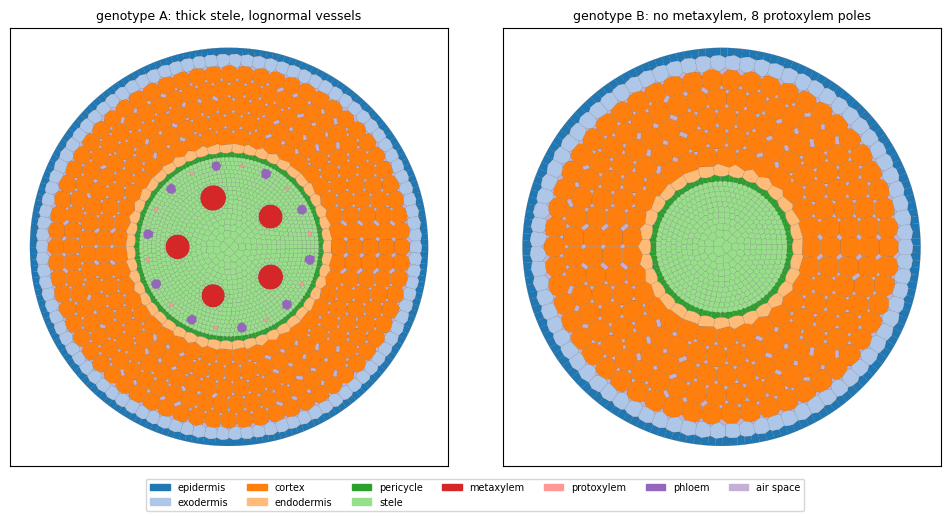

templates: 2 (one per plant parametrization)


In [10]:
class Root(GranapAnatomy):
    library = AnatomyLibrary()


genotypes = ({"granap_overrides": {"stele": {"thickness": 0.45},
                                   "xylem": {"vessel_diameter_distribution": {"family": "lognormal"}}}},
             {"granap_overrides": {"xylem": {"n_vascular_bundles": 0, "n_protoxylem": 8}}})
g3, ds3, _ = build(root_axis([(0.55e-3, 0.)]), Root, scenarios=genotypes)
gallery(g3, ds3, Root, ["genotype A: thick stele, lognormal vessels", "genotype B: no metaxylem, 8 protoxylem poles"], columns=2, size=5)
print("templates:", len(Root.library.templates), "(one per plant parametrization)")

### 3d. Stems, leaves and needles: `shoot`

Other organs are other libraries, by `SubOrgan` label: `shoot = {"LeafElement": OrganAnatomy(library, size=None)}`
(`size=None`: one class, the section does not depend on the segment's radius). Any GRANAP organ class can be the
library's `organ_class`.

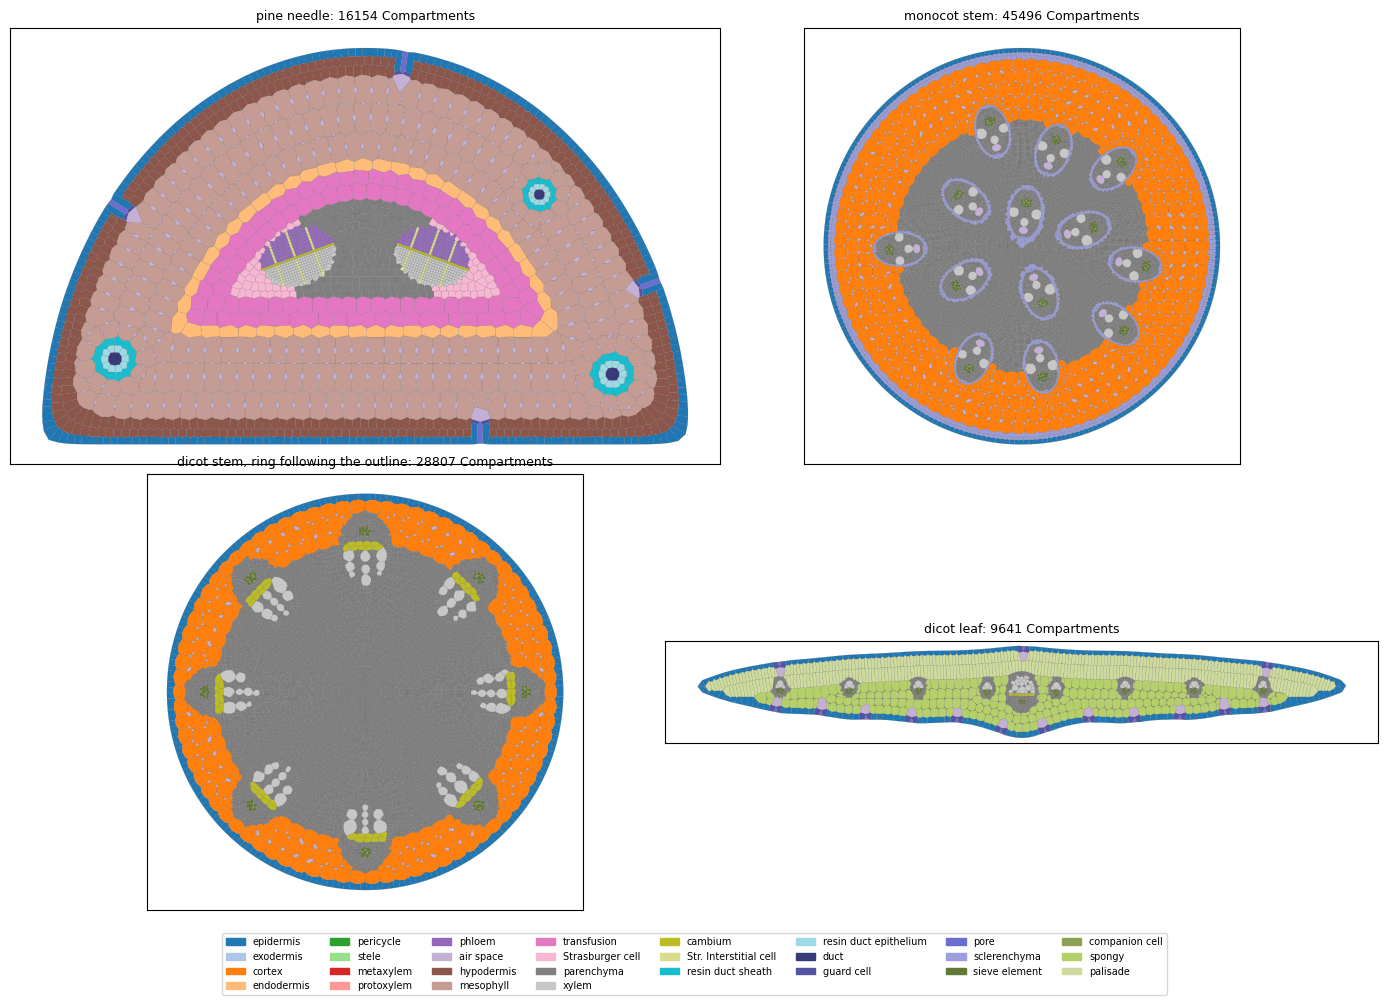

In [12]:
from openalea.granap.leaf_class import LeafAnatomy
from openalea.granap.needle_class import NeedleAnatomy
from openalea.granap.stem_class import StemAnatomy


def shoot_organ(organ_label, element_label):
    class Organ(StructuralComponent):
        @classmethod
        def initiate_plant(cls, g, plant, parameters):
            s, L = g.scales, g.labels
            complex_ = plant
            for scale, label in ((s.Axis, L.Axis.Shoot), (s.GrowthUnit, L.GrowthUnit.Shoot),
                                 (s.Phytomer, L.Phytomer.Shoot), (s.Organ, getattr(L.Organ, organ_label))):
                complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
            v = g.add_component(complex_, **PropsConfig(scale=s.SubOrgan, edge_type='/',
                                                        label=getattr(L.SubOrgan, element_label)))
            g.property("radius")[v], g.property("length")[v], g.property("distance_from_tip")[v] = 1e-3, LENGTH, 0.
    return Organ


shoot_cases = {
    "pine needle": ("Leaf", "LeafElement", NeedleAnatomy, "for_needle"),
    "monocot stem": ("StemInternode", "StemElement", StemAnatomy, "for_monocot_stem"),
    "dicot stem, ring following the outline": ("StemInternode", "StemElement", StemAnatomy, "for_dicot_stem"),
    "dicot leaf": ("Leaf", "LeafElement", LeafAnatomy, "for_dicot_leaf"),
}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (title, (organ_label, element, organ_class, preset)) in zip(axes.flat, shoot_cases.items()):
    overrides = {("vascular_bundle", "ring_shape"): "outline"} if "outline" in title else {}

    def parameters(key, base=None, overrides=None, preset=preset, extra=overrides):
        data = preset_parameters(preset)(key, base=base, overrides=overrides)
        for (section, field), value in extra.items():
            data.set_value(section, field, value)
        return data

    shoot = {element: OrganAnatomy(AnatomyLibrary(parameters=parameters, organ_class=organ_class), size=None)}
    Shoot = type("Shoot", (GranapAnatomy,), {"shoot": shoot})
    gs, dss, _ = build(shoot_organ(organ_label, element), Shoot)
    draw_section(ax, gs, dss, int(dss.entity_ids("SubOrgan")[0]), Shoot,
                 title=f"{title}: {dss.n_nodes()} Compartments")
fig.legend(handles=[matplotlib.patches.Patch(color=c, label=t) for t, c in TISSUE_COLOURS.items()],
           loc="lower center", ncol=8, fontsize=7)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

The leaves' stomatal pores are air nodes, linked to their sub-stomatal chambers; each leaf organ also gets one
"leaf surface" Compartment (`kind` 3) joined to its pores, where a hydraulics model puts the transpiration (MECHA's
tutorials).

## 4. Following the plant's development

The architecture model adds a segment, or a segment changes class (it thickens, ages): at its next call the
component instantiates the class's template there (generating it if it is new), removes the old anatomy if the
class changed, and the DataStructure rewires the new section to its neighbours. `last_update` says what happened.
The component is one instance for the whole simulation, called at each step (here `anatomy2`, from `build`).

In [13]:
segments = sorted(int(v) for v in ds2.entity_ids("SubOrgan"))
tip = g2.add_child(segments[-1], **PropsConfig(scale=g2.scales.SubOrgan, edge_type='<',
                                               label=g2.labels.SubOrgan.RootSegment))
g2.property("radius")[tip], g2.property("length")[tip], g2.property("distance_from_tip")[tip] = 0.40e-3, LENGTH, 0.
radius = ds2.get("radius").copy()                         # and the base segment thickens: a new class
radius[0] = 0.75e-3
ds2.set("radius", radius)
anatomy2()                                                # the same instance, at the next step
print("last update:", anatomy2.last_update)
print(f"{len(MonocotRoot.root.library.templates)} templates for {len(ds2.entity_ids('SubOrgan'))} segments; "
      f"{ds2.n_nodes()} Compartments")
axial = ds2.get("network_path") == 5
print(f"{int(axial.sum())} axial junctions join the sections' xylem and phloem (junction_rules)")

last update: {'emerged': [107364], 'replaced': [16]}
5 templates for 5 segments; 34745 Compartments
105 axial junctions join the sections' xylem and phloem (junction_rules)


## What to take away

- GRANAP's organ classes are unchanged for their users (`RootAnatomy(data, seed=0).generate_cells()` still works);
  in the port they generate into an MPG, so a section is data that other models read, not an object they import.
- A new feature in GRANAP (a field in `OrganInputData`, a new tissue) is available to the component at once, through
  overrides: no component code changes.
- Coupling with hydraulics, solutes or growth is through declared variables: see MECHA's tutorials, starting with
  `tutorial_metafspm_01_granap_mecha.ipynb`.